# Customer Purchase Prediction

Goal: Predict which customers are most likely to make a purchase based on their browsing behavior

## Imports and data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler

import torch
import torch.nn as nn

import warnings
warnings.filterwarnings('ignore')

df = pd.read_csv('/Users/gabrielaslomiany/PycharmProjects/Grey_Matter_Multiplication/Customer Purchase/raw_customer_data.csv')
df.head(10)

,customer_id,time_spent,pages_viewed,basket_value,device_type,customer_type,purchase
0,1,23.097867,7.0,50.574647,Mobile,Returning,0
1,2,57.092144,3.0,56.891022,Mobile,Returning,1
2,3,44.187643,14.0,8.348296,Mobile,Returning,0
3,4,36.320851,10.0,43.481489,Mobile,New,1
4,5,10.205100,16.0,NaN,Mobile,Returning,1
5,6,10.203677,16.0,30.772870,Desktop,Returning,0
6,7,NaN,10.0,19.488900,Mobile,Returning,0
7,8,52.104393,13.0,78.237736,Mobile,Returning,1
8,9,36.465786,NaN,30.668392,Desktop,Returning,1
9,10,42.776282,12.0,NaN,Tablet,NaN,0


## Checking the dataset

In [2]:
df.describe()

,customer_id,time_spent,pages_viewed,basket_value,purchase
count,500.000000,435.000000,458.000000,417.000000,500.000000
mean,250.500000,34.334928,9.777293,49.631566,0.814000
std,144.481833,15.432426,5.520062,27.574666,0.389496
min,1.000000,6.945902,1.000000,0.000000,0.000000
25%,125.750000,20.930505,5.000000,29.929861,1.000000
50%,250.500000,35.037329,9.000000,48.926309,1.000000
75%,375.250000,47.904926,14.000000,70.385368,1.000000
max,500.000000,59.584923,19.000000,130.530372,1.000000


In [3]:
df.dtypes

customer_id        int64
time_spent       float64
pages_viewed     float64
basket_value     float64
device_type          str
customer_type        str
purchase           int64
dtype: object

In [4]:
print(df.isna().sum().sum())
df.isna().sum()

236


customer_id       0
time_spent       65
pages_viewed     42
basket_value     83
device_type      19
customer_type    27
purchase          0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

## Cleaning the dataset

In [6]:
df['customer_id'] = df['customer_id'].astype(int)
df['time_spent'] = df['time_spent'].fillna(df['time_spent'].median()).astype(float)
df['pages_viewed'] = df['pages_viewed'].fillna(df['pages_viewed'].mean()).round().astype(int)
df['basket_value'] = df['basket_value'].fillna(0).astype(float)
df['device_type'] = df['device_type'].fillna('Unknown')
df['customer_type'] = df['customer_type'].fillna('New')
df['purchase'] = df['purchase'].astype(int)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   customer_id    500 non-null    int64  
 1   time_spent     500 non-null    float64
 2   pages_viewed   500 non-null    int64  
 3   basket_value   500 non-null    float64
 4   device_type    500 non-null    str    
 5   customer_type  500 non-null    str    
 6   purchase       500 non-null    int64  
dtypes: float64(2), int64(3), str(2)
memory usage: 27.5 KB


In [7]:
df.columns

Index(['customer_id', 'time_spent', 'pages_viewed', 'basket_value',
       'device_type', 'customer_type', 'purchase'],
      dtype='str')

## Preprocessing

In [9]:
num_cols = ['time_spent', 'pages_viewed', 'basket_value']
df[num_cols] = MinMaxScaler().fit_transform(df[num_cols])

df = pd.get_dummies(
    df,
    columns=['device_type', 'customer_type'],
    dtype=int
)

df.head()

,customer_id,time_spent,pages_viewed,basket_value,purchase,device_type_Desktop,device_type_Mobile,device_type_Tablet,device_type_Unknown,customer_type_New,customer_type_Returning
0,1,0.306844,0.333333,0.387455,0,0,1,0,0,0,1
1,2,0.952644,0.111111,0.435845,1,0,1,0,0,0,1
2,3,0.707493,0.722222,0.063957,0,0,1,0,0,0,1
3,4,0.558045,0.500000,0.333114,1,0,1,0,0,1,0
4,5,0.061916,0.833333,0.000000,1,0,1,0,0,0,1


## Data ready for model

In [10]:
torch.manual_seed(42)

validation = pd.read_csv('validation_features.csv')

feature_cols = [c for c in df.columns if c not in ['customer_id', 'purchase']]
X = torch.tensor(df[feature_cols].values, dtype=torch.float32)
y = torch.tensor(df['purchase'].values, dtype=torch.float32).view(-1, 1)
X_val = torch.tensor(validation[feature_cols].values, dtype=torch.float32)

### Model

In [11]:
purchase_model = nn.Sequential(
    nn.Linear(len(feature_cols), 8),
    nn.ReLU(),
    nn.Linear(8, 1),
    nn.Sigmoid()
)

criterion = nn.BCELoss()
optimizer = torch.optim.Adam(purchase_model.parameters(), lr=0.01)

### Training loop

In [15]:
purchase_model.train()
for epoch in range(500):
    optimizer.zero_grad()
    loss = criterion(purchase_model(X), y)
    loss.backward()
    optimizer.step()

purchase_model.eval()
with torch.no_grad():
    val_probs = purchase_model(X_val).squeeze()

## Result

In [16]:
validation_predictions = pd.DataFrame({
    'customer_id': validation['customer_id'],
    'purchase': (val_probs >= 0.5).int().numpy()
})

validation_predictions.head()

,customer_id,purchase
0,1801,1
1,1802,1
2,1803,1
3,1804,1
4,1805,1


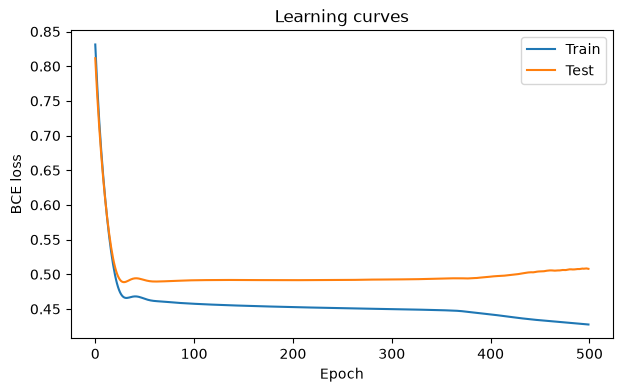

In [23]:
def build_model():
    torch.manual_seed(42)
    return nn.Sequential(
        nn.Linear(len(feature_cols), 8), nn.ReLU(),
        nn.Linear(8, 1), nn.Sigmoid()
    )

model = build_model()
criterion = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
history = {'train': [], 'test': []}

for epoch in range(500):
    model.train()
    optimizer.zero_grad()
    loss = criterion(model(X_train), y_train)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        history['train'].append(loss.item())
        history['test'].append(criterion(model(X_test), y_test).item())

plt.figure(figsize=(7, 4))
plt.plot(history['train'], label='Train')
plt.plot(history['test'], label='Test')
plt.xlabel('Epoch'); plt.ylabel('BCE loss'); plt.title('Learning curves')
plt.legend(); plt.show()

**Learning curves:** Test loss is lowest at around epoch 30 to 60 ($\approx 0.49$). After epoch $\approx 370$ it rises while train loss keeps falling, which indicates overfitting. The minimum test loss is about equal to the constant base-rate predictor ($\approx 0.48$), so the model adds little information beyond the class prior.

**Overfitting and sample size:** The small dataset (400 training rows, $\approx 74$ non-purchasers) makes noise easier to memorise. However, the network has only 89 parameters, and the test loss never beats the base-rate predictor. The main limitation is therefore weak predictive signal in the features, with the small sample amplifying it.